# 03 — q99 precursor discovery

## Research question

Can information observable **before** a native five-minute q99 volatility event distinguish that event from comparable non-event moments?

The q99 event is defined inside this module from the current five-minute return:

\[
v_t=r_t^2,\qquad q99_i=Q_{0.99}(v_{i,t}).
\]

Only the **first bar of a consecutive q99 run** is treated as an event onset.

## Independence contract

This module does not import feature rankings, models, coefficients, state labels, thresholds, or conclusions from any other research branch. It also does not consume Module 01/02 output files.

The q99 threshold is recomputed from `return_5m` here. Predictor fields are discovered directly from the current `time_series_feature_state` schema at runtime. Every numeric or boolean field is eligible except identifiers.

## Information boundary

For precursor ranking:

\[
t<t_0\quad\text{only}.
\]

The q99 candle at (t_0) and later candles are used only for descriptive event anatomy, never as precursor inputs.


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 180)
pd.set_option('display.width', 280)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_q99_precursors as qp

START = os.getenv('VD3_START', '').strip() or None
END = os.getenv('VD3_END', '').strip() or None
ASSET_FILTER = [x.strip().upper() for x in os.getenv('VD3_ASSETS', '').split(',') if x.strip()]
MAX_CONTROLS = int(os.getenv('VD3_MAX_CONTROLS', str(qp.DEFAULT_MAX_CONTROLS)))
MIN_CONTROLS = int(os.getenv('VD3_MIN_CONTROLS', str(qp.DEFAULT_MIN_CONTROLS)))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '03'
OUT.mkdir(parents=True, exist_ok=True)

print('q99 precursor engine', qp.VERSION)
print('selftest:', qp.selftest())
print('window:', START or 'earliest available', '->', END or 'latest available')
print('controls per event: max', MAX_CONTROLS, '| minimum usable', MIN_CONTROLS)


q99 precursor engine 0.1.0
selftest: {'q99_recomputed': True, 'run_onset_only': True, 'same_clock_controls': True, 'strict_pre_event_boundary': True, 'known_precursor_recovered': True}
window: earliest available -> latest available
controls per event: max 8 | minimum usable 4


## 1. Discover all eligible predictors from the shared feature table

No hand-picked feature family is used. The database schema itself determines the numeric/boolean candidate set. String/categorical fields and identifiers are excluded from quantitative ranking.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
schema = con.execute('DESCRIBE time_series_feature_state').df()
predictors, feature_inventory = qp.eligible_predictor_columns(schema)
print('eligible numeric/boolean predictors:', len(predictors))
display(feature_inventory[feature_inventory.eligible_predictor].head(100))

def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

select_cols = list(dict.fromkeys(['state_time','underlying','return_5m'] + predictors))
where = []
if START:
    where.append(f"state_time >= TIMESTAMPTZ '{pd.Timestamp(START, tz='UTC').isoformat()}'")
if END:
    end_ts = pd.Timestamp(END, tz='UTC') + pd.Timedelta(days=1)
    where.append(f"state_time < TIMESTAMPTZ '{end_ts.isoformat()}'")
if ASSET_FILTER:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSET_FILTER) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
sql = (
    'SELECT ' + ', '.join(qident(c) for c in select_cols)
    + ' FROM time_series_feature_state' + where_sql
    + ' ORDER BY underlying, state_time'
)
df = con.execute(sql).df()
con.close()
df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
df = df.reset_index(drop=True)
if df.empty:
    raise RuntimeError('No rows found.')
dupes = int(df.duplicated(['underlying','state_time']).sum())
if dupes:
    raise RuntimeError(f'Found {dupes} duplicate asset/timestamp rows.')
print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())}')
print(df.state_time.min(), '->', df.state_time.max())


eligible numeric/boolean predictors: 205


,feature,duckdb_type,eligible_predictor,reason
7,minutes_to_expiry,BIGINT,True,numeric_or_boolean
8,is_opening_state,BOOLEAN,True,numeric_or_boolean
9,utc_hour,BIGINT,True,numeric_or_boolean
10,utc_minute_of_day,BIGINT,True,numeric_or_boolean
11,utc_day_of_week,BIGINT,True,numeric_or_boolean
12,is_weekend,BOOLEAN,True,numeric_or_boolean
14,us_dst,BOOLEAN,True,numeric_or_boolean
15,eu_dst,BOOLEAN,True,numeric_or_boolean
16,perp_integrity_ok,BOOLEAN,True,numeric_or_boolean
17,integrity_flag_count,INTEGER,True,numeric_or_boolean


rows 38,304 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-08 07:55:00+00:00


## 2. Recompute q99 event onsets from raw `return_5m`

Consecutive q99 bars are one event: only the first q99 bar is the anchor. This prevents a two- or three-bar extreme run from being counted as several independent event starts.


In [3]:
events, event_meta = qp.identify_q99_onsets(df)
if events.empty:
    raise RuntimeError('No q99 event onsets found.')
display(event_meta)
print('asset-event onsets:', len(events), '| unique event timestamps:', events.event_time.nunique())
display(events.head(30))


,underlying,threshold,n_finite_returns,n_q99_bars,n_q99_onsets
0,AVAX,0.000099,4716,48,45
1,BTC,0.000014,4716,48,41
2,ETH,0.000019,4716,48,41
3,HYPE,0.000042,4716,48,46
4,SOL,0.000035,4716,48,43
5,TRX,0.000003,4714,48,45
6,XRP,0.000054,4716,48,42


asset-event onsets: 303 | unique event timestamps: 180


,event_id,underlying,event_time,event_panel_index,clock_slot,q99_threshold,event_variance_5m,previous_variance_5m
0,1,AVAX,2026-09-21 17:55:00+00:00,695,215,0.000099,0.000211,9.579843e-06
1,2,AVAX,2026-09-22 15:25:00+00:00,953,185,0.000099,0.000099,1.600281e-06
2,3,AVAX,2026-09-23 03:50:00+00:00,1102,46,0.000099,0.000204,2.532562e-05
3,4,AVAX,2026-09-23 10:40:00+00:00,1184,128,0.000099,0.000099,0.000000e+00
4,5,AVAX,2026-09-23 12:05:00+00:00,1201,145,0.000099,0.000530,7.267898e-06
5,6,AVAX,2026-09-23 13:55:00+00:00,1223,167,0.000099,0.000148,NaN
6,7,AVAX,2026-09-23 14:10:00+00:00,1226,170,0.000099,0.000152,5.511437e-07
7,8,AVAX,2026-09-23 14:35:00+00:00,1231,175,0.000099,0.000169,1.079975e-05
8,9,AVAX,2026-09-23 16:10:00+00:00,1250,194,0.000099,0.000173,8.054198e-06
9,10,AVAX,2026-09-24 05:35:00+00:00,1411,67,0.000099,0.000108,4.570228e-07


## 3. Same-asset, exact-clock nearby-date controls

For each q99 onset, controls are non-q99 origins from the **same asset and exact five-minute UTC clock slot**. The nearest dates are used first. A control whose immediately preceding exact bar is q99 is excluded.

This is not an attempt to explain events by time of day. Clock is treated only as a nuisance condition so ordinary intraday patterns do not masquerade as precursors.


In [4]:
origins = qp.build_origin_index(df, events)
controls = qp.choose_controls(origins, events, max_controls=MAX_CONTROLS)
control_support = (
    controls.groupby('event_id').agg(
        n_controls=('control_panel_index','size'),
        nearest_days=('distance_days','min'),
        furthest_days=('distance_days','max'),
    ).reset_index()
)
events_with_support = events.merge(control_support, on='event_id', how='left')
display(events_with_support.n_controls.describe())
display(events_with_support.sort_values('n_controls').head(30))


count    303.0
mean       8.0
std        0.0
min        8.0
25%        8.0
50%        8.0
75%        8.0
max        8.0
Name: n_controls, dtype: float64

,event_id,underlying,event_time,event_panel_index,clock_slot,q99_threshold,event_variance_5m,previous_variance_5m,n_controls,nearest_days,furthest_days
0,1,AVAX,2026-09-21 17:55:00+00:00,695,215,0.000099,0.000211,9.579843e-06,8,1.0,9.0
1,2,AVAX,2026-09-22 15:25:00+00:00,953,185,0.000099,0.000099,1.600281e-06,8,1.0,8.0
2,3,AVAX,2026-09-23 03:50:00+00:00,1102,46,0.000099,0.000204,2.532562e-05,8,1.0,7.0
3,4,AVAX,2026-09-23 10:40:00+00:00,1184,128,0.000099,0.000099,0.000000e+00,8,1.0,8.0
4,5,AVAX,2026-09-23 12:05:00+00:00,1201,145,0.000099,0.000530,7.267898e-06,8,1.0,8.0
5,6,AVAX,2026-09-23 13:55:00+00:00,1223,167,0.000099,0.000148,NaN,8,1.0,6.0
6,7,AVAX,2026-09-23 14:10:00+00:00,1226,170,0.000099,0.000152,5.511437e-07,8,1.0,7.0
7,8,AVAX,2026-09-23 14:35:00+00:00,1231,175,0.000099,0.000169,1.079975e-05,8,1.0,8.0
8,9,AVAX,2026-09-23 16:10:00+00:00,1250,194,0.000099,0.000173,8.054198e-06,8,1.0,6.0
9,10,AVAX,2026-09-24 05:35:00+00:00,1411,67,0.000099,0.000108,4.570228e-07,8,1.0,7.0


## 4. Feature coverage

Every eligible numeric/boolean feature is carried forward. Sparse fields are not imputed; they simply receive fewer usable event/control comparisons.


In [5]:
coverage = qp.feature_coverage(df, predictors)
display(coverage.sort_values('coverage').head(80))


,feature,n_rows,n_finite,coverage
31,futures_underlying_price,38304,0,0.000000
73,mid_path_valid_points,38304,7364,0.192251
75,mid_path_realized_variance,38304,7364,0.192251
74,mid_path_increment_count,38304,7364,0.192251
78,mid_path_return_sign_flips,38304,7364,0.192251
77,mid_path_nonzero_increments,38304,7364,0.192251
79,mid_path_max_abs_log_return,38304,7364,0.192251
76,mid_path_zero_increments,38304,7364,0.192251
80,book_out_of_order_update_count,38304,9681,0.252741
72,book_obi_20_reversal_strength_max,38304,13383,0.349389


## 5. Event anatomy from -60m to +60m

For every feature and relative bar, the event value is converted to its percentile among that event's same-clock controls.

A score of:

- `0.50` means typical;
- `0.90` means unusually high relative to controls;
- `0.10` means unusually low.

Only negative relative times are eligible as precursor evidence. `0` and positive times are anatomy only.


In [6]:
relative_bars = range(-12, 13)
scores = qp.percentile_scores(
    df, predictors, events, controls, relative_bars,
    min_controls=MIN_CONTROLS,
)
if scores.empty:
    raise RuntimeError('No usable event/control feature comparisons.')
profiles = qp.summarize_profiles(scores)
by_asset = qp.summarize_by_asset(scores)
print('event-feature-lag comparisons:', f'{len(scores):,}')
print('compact profile rows:', f'{len(profiles):,}')


event-feature-lag comparisons: 1,313,406
compact profile rows: 4,925


## 6. Exploratory precursor ranking

The ranking uses only (-60,-30,-15,-10,-5) minute observations.

To reduce false discoveries from synchronized multi-asset events, all asset-events sharing an exact event timestamp are averaged first. A candidate is then penalized if its direction is inconsistent across assets or across the five pre-event lags.

`discovery_score` is an exploratory prioritization metric, **not** a p-value and not evidence of predictability.


In [7]:
rankings = qp.precursor_rankings(scores)
display(rankings.head(80).round(4))


,feature,best_rel_bar,best_rel_min,n_unique_event_times,n_assets,mean_percentile,median_percentile,direction,abs_deviation_from_half,mean_abs_deviation_across_rank_lags,assets_consistent_direction,asset_direction_consistency,lag_direction_consistency,discovery_score
0,book_obi_20_raw_zero_cross_count,-6,-30,39,7,0.7342,0.8000,high_before_event,0.2342,0.1871,7,1.0000,1.0,0.2342
1,book_obi_20_transition_count,-6,-30,39,7,0.7255,0.7500,high_before_event,0.2255,0.1883,7,1.0000,1.0,0.2255
2,intrabar_range_bps,-1,-5,144,7,0.7152,0.7500,high_before_event,0.2152,0.1736,7,1.0000,1.0,0.2152
3,book_obi_20_raw_zero_cross_rate,-6,-30,39,7,0.6994,0.8000,high_before_event,0.1994,0.1497,7,1.0000,1.0,0.1994
4,iv_put_25d,-3,-15,149,7,0.6986,0.7500,high_before_event,0.1986,0.1781,7,1.0000,1.0,0.1986
5,book_obi_20_path_roughness_per_min,-1,-5,40,7,0.6960,0.7500,high_before_event,0.1960,0.1512,7,1.0000,1.0,0.1960
6,realized_vol_1h,-1,-5,155,7,0.6920,0.7500,high_before_event,0.1920,0.1730,7,1.0000,1.0,0.1920
7,realized_vol_1h_annualized,-1,-5,155,7,0.6920,0.7500,high_before_event,0.1920,0.1730,7,1.0000,1.0,0.1920
8,realized_vol_4h,-2,-10,82,7,0.6908,0.8000,high_before_event,0.1908,0.1814,7,1.0000,1.0,0.1908
9,realized_vol_4h_annualized,-2,-10,82,7,0.6908,0.8000,high_before_event,0.1908,0.1814,7,1.0000,1.0,0.1908


## 7. Inspect the leading precursor trajectories

The plot is the mean same-clock percentile around q99 onset. The horizontal 0.5 line is a typical control value. The vertical line at 0 marks the q99 event candle.


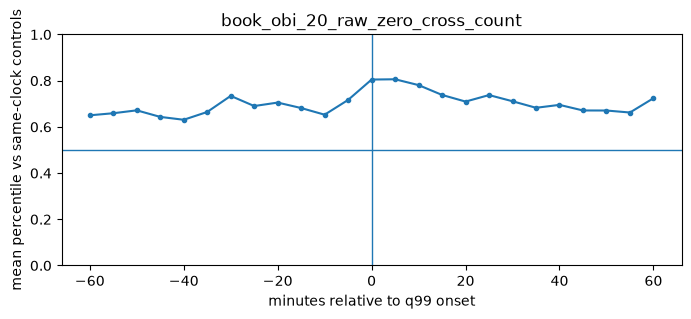

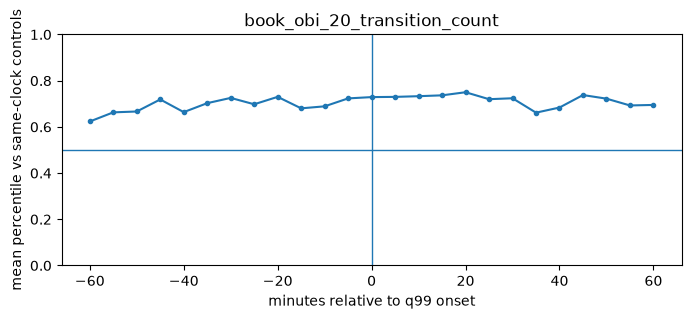

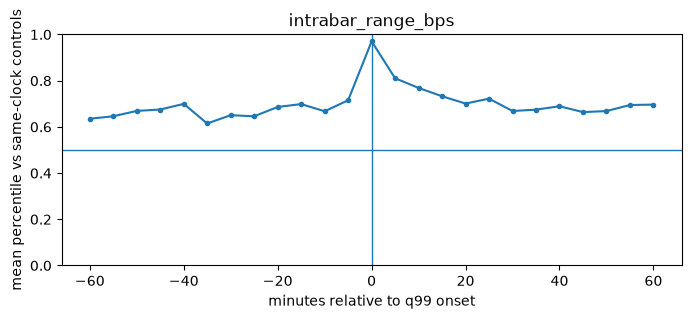

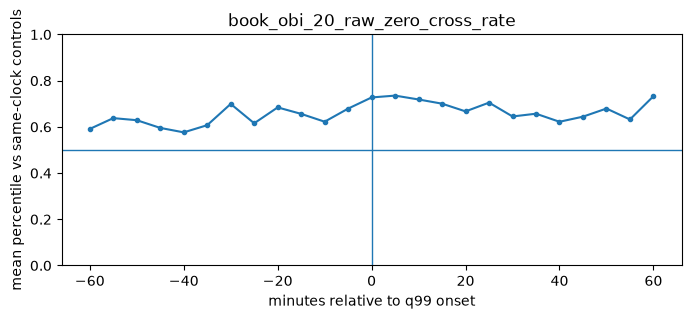

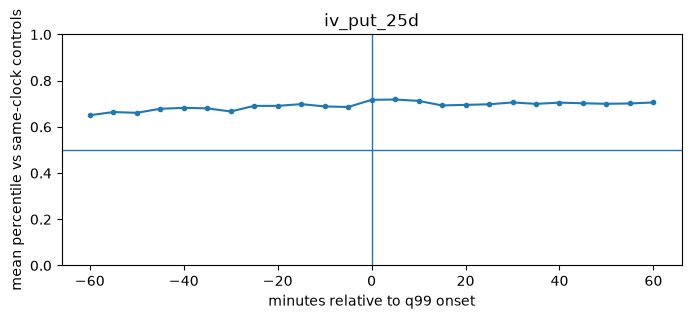

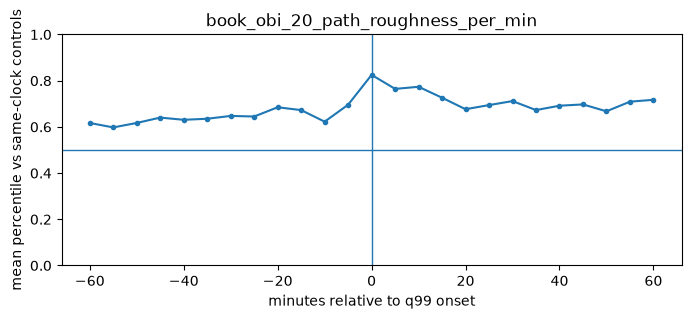

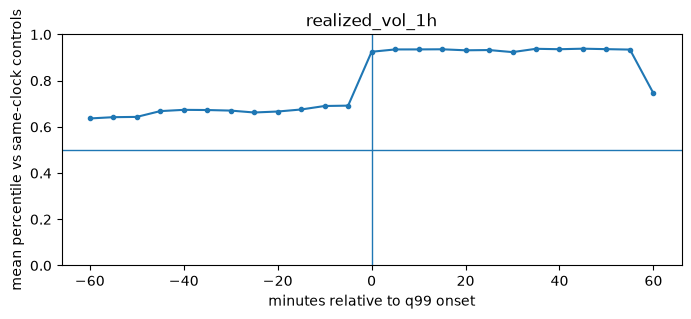

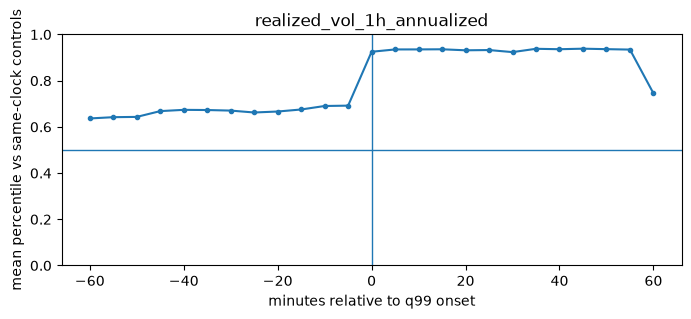

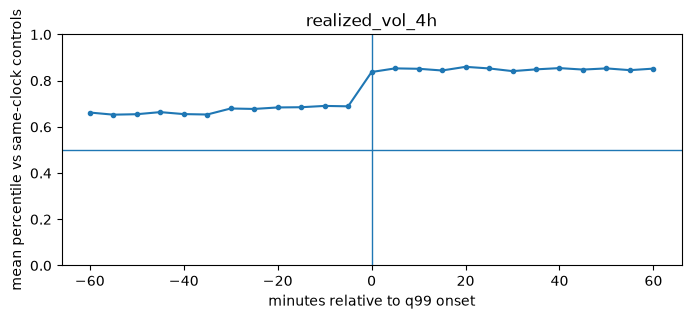

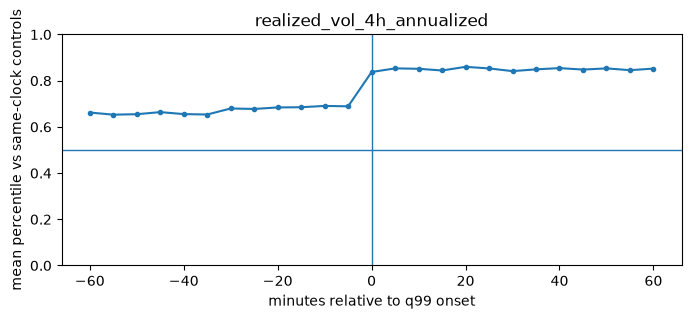

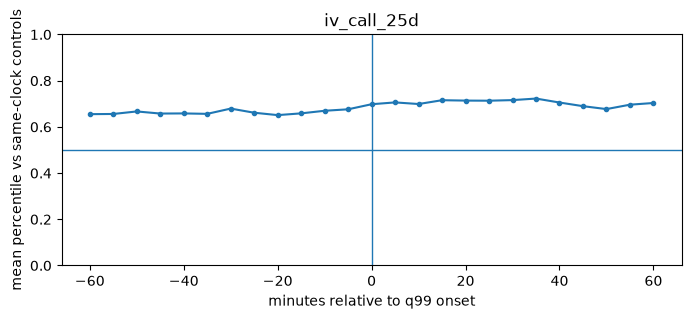

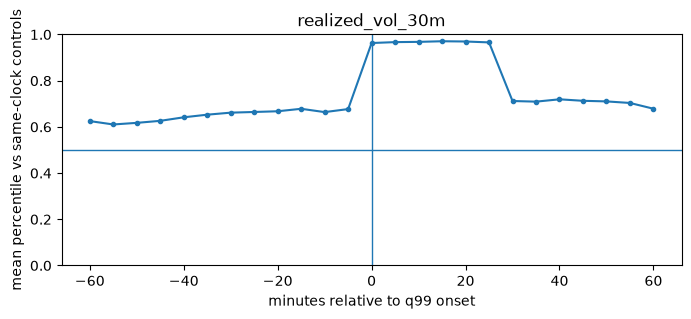

In [8]:
top_features = rankings.head(12)['feature'].tolist() if len(rankings) else []
for feature in top_features:
    g = profiles[profiles.feature == feature].sort_values('rel_min')
    if not len(g):
        continue
    fig, ax = plt.subplots(figsize=(8,3))
    ax.plot(g.rel_min, g.mean_percentile, marker='o', markersize=3)
    ax.axhline(0.5, linewidth=1)
    ax.axvline(0, linewidth=1)
    ax.set_ylim(0,1)
    ax.set_title(feature)
    ax.set_xlabel('minutes relative to q99 onset')
    ax.set_ylabel('mean percentile vs same-clock controls')
    plt.show()


## 8. Compact audit tables for the strongest candidates

This keeps enough event-level information to audit a candidate later without committing the full million-row score table.


In [9]:
top20 = set(rankings.head(20)['feature']) if len(rankings) else set()
top_event_scores = scores[
    scores.feature.isin(top20)
    & scores.rel_bar.isin(qp.DEFAULT_RANK_LAGS)
].copy()
display(top_event_scores.head(100))


,event_id,underlying,event_time,feature,rel_bar,rel_min,is_precursor,n_controls,percentile_vs_controls,robust_diff_iqr,event_value,control_median
44,1,AVAX,2026-09-21 17:55:00+00:00,volume_usd,-12,-60,True,8,0.125000,-0.363127,3843.712903,6405.834046
47,1,AVAX,2026-09-21 17:55:00+00:00,trade_count,-12,-60,True,8,0.500000,-0.273684,11.000000,17.500000
55,1,AVAX,2026-09-21 17:55:00+00:00,log1p_volume_usd,-12,-60,True,8,0.125000,-0.788179,8.254454,8.762662
60,1,AVAX,2026-09-21 17:55:00+00:00,intrabar_range_bps,-12,-60,True,8,0.125000,-1.333056,7.205909,25.309379
69,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_30m,-12,-60,True,6,0.833333,0.612161,0.006957,0.006045
70,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_30m_annualized,-12,-60,True,6,0.833333,0.612161,0.920869,0.800151
71,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_1h,-12,-60,True,6,0.666667,0.402629,0.012953,0.010689
72,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_1h_annualized,-12,-60,True,6,0.666667,0.402629,1.212316,1.000462
73,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_4h,-12,-60,True,4,0.500000,-0.172842,0.022303,0.024213
74,1,AVAX,2026-09-21 17:55:00+00:00,realized_vol_4h_annualized,-12,-60,True,4,0.500000,-0.172842,1.043746,1.133086


## 9. Persist compact outputs


In [10]:
feature_inventory.to_csv(OUT / '03_feature_inventory.csv', index=False)
coverage.to_csv(OUT / '03_feature_coverage.csv', index=False)
event_meta.to_csv(OUT / '03_q99_thresholds_and_counts.csv', index=False)
events_with_support.to_csv(OUT / '03_q99_event_origins.csv', index=False)
controls.to_csv(OUT / '03_matched_controls.csv', index=False)
profiles.to_csv(OUT / '03_feature_event_profiles.csv', index=False)
by_asset.to_csv(OUT / '03_precursor_by_asset.csv', index=False)
rankings.to_csv(OUT / '03_precursor_rankings.csv', index=False)
top_event_scores.to_csv(OUT / '03_top_candidate_event_scores.csv', index=False)

meta = {
    'version': qp.VERSION,
    'module': '03_q99_precursor_discovery',
    'research_question': 'Do numeric/boolean market-state fields observable before a native 5m q99 volatility onset differ from same-asset exact-clock non-event controls?',
    'database_relation': 'time_series_feature_state',
    'event_definition': 'asset-specific full-sample q99 of return_5m**2; consecutive q99 runs reduced to first bar',
    'q99_recomputed_inside_module': True,
    'predictor_source': 'all runtime-discovered numeric/boolean fields except identifiers',
    'strict_precursor_boundary': 'relative_bar < 0 only',
    'event_and_post_bars_for_anatomy_only': True,
    'control_matching': 'same asset, exact 5m UTC clock slot, nearest eligible dates',
    'max_controls_per_event': MAX_CONTROLS,
    'min_controls_per_feature_event': MIN_CONTROLS,
    'ranking_lags_minutes': [-60,-30,-15,-10,-5],
    'synchronous_asset_weighting': 'asset-events sharing exact timestamp averaged before pooled ranking',
    'no_predictive_model': True,
    'no_p_value_claim': True,
    'start': START or 'earliest_available',
    'end': END or 'latest_available',
    'n_rows': int(len(df)),
    'n_predictors': int(len(predictors)),
    'n_asset_event_onsets': int(len(events)),
    'n_unique_event_times': int(events.event_time.nunique()),
}
(OUT / '03_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote Module 03 outputs to', OUT)


wrote Module 03 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\03


## Interpretation boundary

A high ranking means a feature was repeatedly unusual **before** q99 events relative to nearby-date, same-asset, same-clock controls.

It does **not** yet prove that the feature predicts future q99 events out of sample. If coherent candidates emerge, the next module should freeze those candidates and test them prospectively/chronologically against non-event origins.
